# Prelude

In [1]:
%cd /home/mfixman/TP/MyPyCop

/home/mfixman/Dropbox/continuous/TP/MyPyCop


In [2]:
import pandas
import scipy
import numpy
import matplotlib
import seaborn
import json
import glob

from matplotlib import pyplot

from pandas import Series, DataFrame

In [3]:
seaborn.set()

# Getting Data

In [4]:
%pwd

'/home/mfixman/Dropbox/continuous/TP/MyPyCop'

In [5]:
data = pandas.concat([
    pandas.read_csv(
        'results/tuesday_final.csv',
    ),
    # pandas.read_csv(
      # 'results/literal_untie.csv',
    # )
])

In [7]:
strategies = data.strategy.unique()
strategies

array(['FirstAction', 'LeanCopCut', 'SATSolveLiteral',
       'SATSolveLiteralRareStart', 'SATSolveLiteralModelStart',
       'SATSolveLiteralFirstStart'], dtype=object)

In [7]:
# problems = data.xs(level = 'strategy', key = 'SATSolveGuided').index.str[:3].unique()
# data = data[data.index.get_level_values('problem').str[:3].isin(problems)]
# problems

In [8]:
# data = data.groupby(level = 'problem').filter(lambda x: x.solved.count() == len(strategies))

In [8]:
data.problem.str[:3].unique()

array(['AGT', 'ALG', 'ANA', 'BIO', 'BOO', 'CAT', 'COL', 'COM', 'CSR',
       'FLD', 'GEG', 'GEO', 'GRA', 'GRP', 'HAL', 'HEN', 'HWC', 'HWV',
       'ITP', 'KLE', 'KRS', 'LAT', 'LCL', 'LDA', 'MED', 'MGT', 'MSC',
       'MVA', 'NLP', 'NUM', 'NUN', 'PHI', 'PLA', 'PRD', 'PRO', 'PUZ',
       'REL', 'RNG', 'ROB', 'SCT', 'SET', 'SEU', 'SEV', 'SWB', 'SWC',
       'SWV', 'SWW', 'SYN', 'SYO', 'TOP'], dtype=object)

# Analysing

In [9]:
control = ['FirstAction', 'LeanCopCut']

In [10]:
data[data.solved]

,problem,strategy,status,solved,steps,time_ms,info,error
0,AGT001+1.p,FirstAction,solved,True,4.0,2.0,Theorem,NaN
1,AGT001+1.p,LeanCopCut,solved,True,4.0,3.0,Theorem,NaN
2,AGT001+1.p,SATSolveLiteral,solved,True,0.0,0.0,Theorem (SAT),NaN
3,AGT001+1.p,SATSolveLiteralRareStart,solved,True,0.0,0.0,Theorem (SAT),NaN
4,AGT001+1.p,SATSolveLiteralModelStart,solved,True,0.0,0.0,Theorem (SAT),NaN
...,...,...,...,...,...,...,...,...
99419,TOP005-2.p,SATSolveLiteralFirstStart,solved,True,27599.0,29607.0,"Theorem (SAT); literal=choices:16360,forward:4...",NaN
99452,TOP026+1.p,SATSolveLiteral,solved,True,8243.0,12643.0,"Theorem (SAT); literal=choices:4441,forward:95...",NaN
99453,TOP026+1.p,SATSolveLiteralRareStart,solved,True,7879.0,12215.0,"Theorem (SAT); literal=choices:4238,forward:88...",NaN
99454,TOP026+1.p,SATSolveLiteralModelStart,solved,True,8243.0,10147.0,"Theorem (SAT); literal=choices:4429,forward:94...",NaN


In [13]:
data[data.solved].groupby('strategy').size()

strategy
FirstAction                  1729
LeanCopCut                   1919
SATSolveLiteral              2510
SATSolveLiteralFirstStart    2486
SATSolveLiteralModelStart    2495
SATSolveLiteralRareStart     2495
dtype: int64

In [15]:
solved = data.pivot(columns = 'strategy', values = 'solved')

In [16]:
solved[solved.sum(axis = 1) == 1].sum(axis = 0)

strategy
FirstAction                  1729
LeanCopCut                   1919
SATSolveLiteral              2510
SATSolveLiteralFirstStart    2486
SATSolveLiteralModelStart    2495
SATSolveLiteralRareStart     2495
dtype: object

# Results

<Axes: xlabel='strategy'>

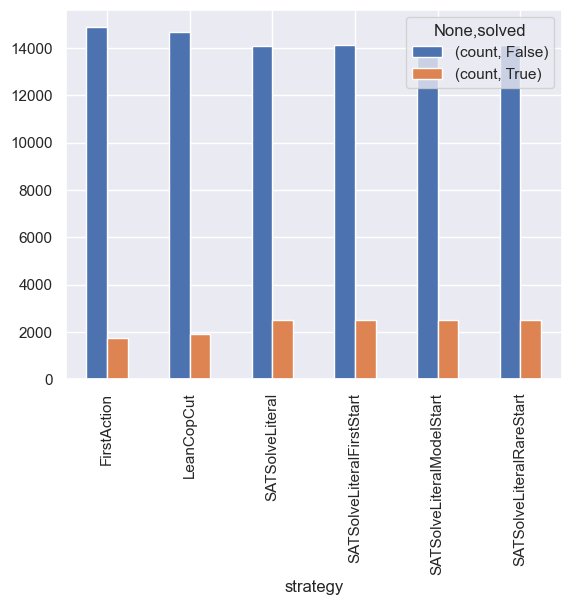

In [18]:
data.groupby('strategy').solved.value_counts().to_frame().reset_index('solved').pivot(columns = 'solved').plot.bar()

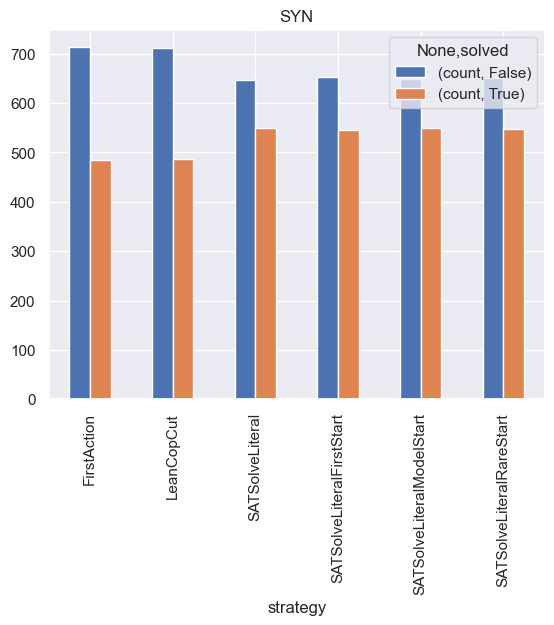

In [20]:
data[data.problem.str[:3] == 'SYN'].groupby('strategy').solved.value_counts().to_frame().reset_index('solved').pivot(columns = 'solved').plot.bar()
pyplot.title('SYN')
None

In [28]:
all(merged.index.get_level_values('strategy_left') == merged.index.get_level_values('strategy_right'))

True

In [35]:
merged

,,,problem,status_left,solved_left,steps_left,time_ms_left,info_left,error_left,status_right,solved_right,steps_right,time_ms_right,info_right,error_right
,strategy_left,strategy_right,,,,,,,,,,,,,
0,FirstAction,FirstAction,AGT001+1.p,solved,True,4.0,2.0,Theorem,NaN,solved,True,4.0,2.0,Theorem,NaN
1,FirstAction,LeanCopCut,AGT001+1.p,solved,True,4.0,2.0,Theorem,NaN,solved,True,4.0,3.0,Theorem,NaN
2,FirstAction,SATSolveLiteral,AGT001+1.p,solved,True,4.0,2.0,Theorem,NaN,solved,True,0.0,0.0,Theorem (SAT),NaN
3,FirstAction,SATSolveLiteralRareStart,AGT001+1.p,solved,True,4.0,2.0,Theorem,NaN,solved,True,0.0,0.0,Theorem (SAT),NaN
4,FirstAction,SATSolveLiteralModelStart,AGT001+1.p,solved,True,4.0,2.0,Theorem,NaN,solved,True,0.0,0.0,Theorem (SAT),NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
597415,SATSolveLiteralFirstStart,LeanCopCut,TOP052-1.p,timeout,False,214148.0,120001.0,"literal=choices:106707,forward:7790469,unique:...",NaN,timeout,False,190572.0,120002.0,NaN,NaN
597416,SATSolveLiteralFirstStart,SATSolveLiteral,TOP052-1.p,timeout,False,214148.0,120001.0,"literal=choices:106707,forward:7790469,unique:...",NaN,timeout,False,196154.0,120000.0,"literal=choices:97740,forward:7135695,unique:6...",NaN
597417,SATSolveLiteralFirstStart,SATSolveLiteralRareStart,TOP052-1.p,timeout,False,214148.0,120001.0,"literal=choices:106707,forward:7790469,unique:...",NaN,timeout,False,86001.0,120000.0,"literal=choices:42853,forward:3130882,unique:2...",NaN


<Axes: xlabel='winner', ylabel='loser'>

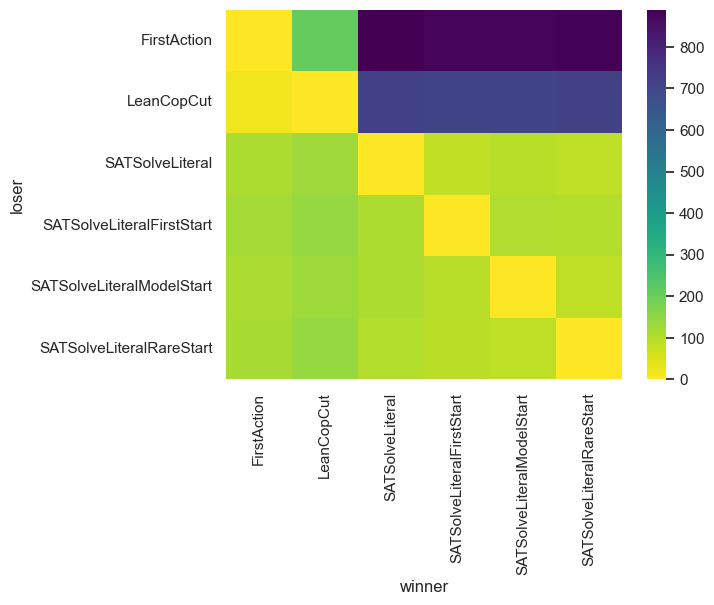

In [54]:
merged = pandas.merge(
    data,
    data,
    left_on = 'problem',
    right_on = 'problem',
    suffixes = ('_left', '_right'),
)

# merged = merged[merged.strategy_left < merged.strategy_right]
results = (
    merged
    [~merged.solved_left & merged.solved_right]
    [['strategy_left', 'strategy_right']]
    .value_counts()
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'loser', columns = 'winner')
)

seaborn.heatmap(results, cmap = 'viridis_r')

# Analysis